# GoEmotions – Emotion Detection from Text
### Pipeline Amélioré v2: Class Weights · TF-IDF optimisé · 6 Modèles · GridSearch · F1 Evaluation
**Dataset:** Google GoEmotions (28 emotion classes)

## 1. Setup & Data Loading

In [ ]:
# Install dependencies
!pip install pandas numpy matplotlib seaborn scikit-learn nltk datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

import nltk
nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [ ]:
# ── Option A: Load from local files (original approach) ────────────────────────
# Uncomment and adjust path if you have the CSV files:
# train = pd.read_csv("full_dataset/goemotions_1.csv")
# test  = pd.read_csv("full_dataset/goemotions_2.csv")
# dev   = pd.read_csv("full_dataset/goemotions_3.csv")
# df_raw = pd.concat([train, test, dev], ignore_index=True)

# ── Option B: Load from HuggingFace (recommended – always works) ───────────────
from datasets import load_dataset
dataset = load_dataset("google-research-datasets/go_emotions", "simplified")

# Combine all splits into one DataFrame
splits = []
for split in ["train", "validation", "test"]:
    tmp = dataset[split].to_pandas()
    splits.append(tmp)

df_raw = pd.concat(splits, ignore_index=True)
print("Raw shape:", df_raw.shape)
print(df_raw.head())

README.md: 0.00B [00:00, ?B/s]

simplified/train-00000-of-00001.parquet:   0%|          | 0.00/2.77M [00:00<?, ?B/s]

simplified/validation-00000-of-00001.par(…):   0%|          | 0.00/350k [00:00<?, ?B/s]

simplified/test-00000-of-00001.parquet:   0%|          | 0.00/347k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

Raw shape: (54263, 3)
                                                text labels       id
0  My favourite food is anything I didn't have to...   [27]  eebbqej
1  Now if he does off himself, everyone will thin...   [27]  ed00q6i
2                     WHY THE FUCK IS BAYLESS ISOING    [2]  eezlygj
3                        To make her feel threatened   [14]  ed7ypvh
4                             Dirty Southern Wankers    [3]  ed0bdzj


## 2. Label Assignment (Bug Fix)

> **⚠️ Original bug:** The original code used `idxmax()` on binary emotion columns, which doesn't correctly handle the GoEmotions simplified format where labels are stored as a list.  
> **Fix:** We explode the labels list and keep single-label examples for clean multi-class classification.

In [ ]:
# GoEmotions simplified format: 'labels' is a list of integer label IDs
# Label ID → emotion name mapping
EMOTION_NAMES = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
    'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
    'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization',
    'relief', 'remorse', 'sadness', 'surprise', 'neutral'
]

# Keep only single-label examples (cleaner for multi-class classification)
df_raw['n_labels'] = df_raw['labels'].apply(len)
df_single = df_raw[df_raw['n_labels'] == 1].copy()

# Map label ID to emotion name
df_single['label'] = df_single['labels'].apply(lambda x: EMOTION_NAMES[x[0]])

# Keep only what we need
df = df_single[['text', 'label']].reset_index(drop=True)

print(f"Total single-label examples: {len(df)}")
print(f"(Dropped {len(df_raw) - len(df)} multi-label examples)")
print("\nLabel distribution:")
print(df['label'].value_counts())

Total single-label examples: 45446
(Dropped 8817 multi-label examples)

Label distribution:
label
neutral           16021
admiration         3384
gratitude          2378
approval           2367
amusement          2046
disapproval        1809
annoyance          1809
love               1760
curiosity          1729
anger              1265
optimism           1087
confusion          1057
joy                1052
sadness            1003
surprise            902
disappointment      888
caring              831
realization         749
disgust             635
excitement          619
fear                553
desire              497
remorse             437
embarrassment       246
nervousness         105
relief              103
pride                67
grief                47
Name: count, dtype: int64


## 3. Exploratory Data Analysis (EDA)

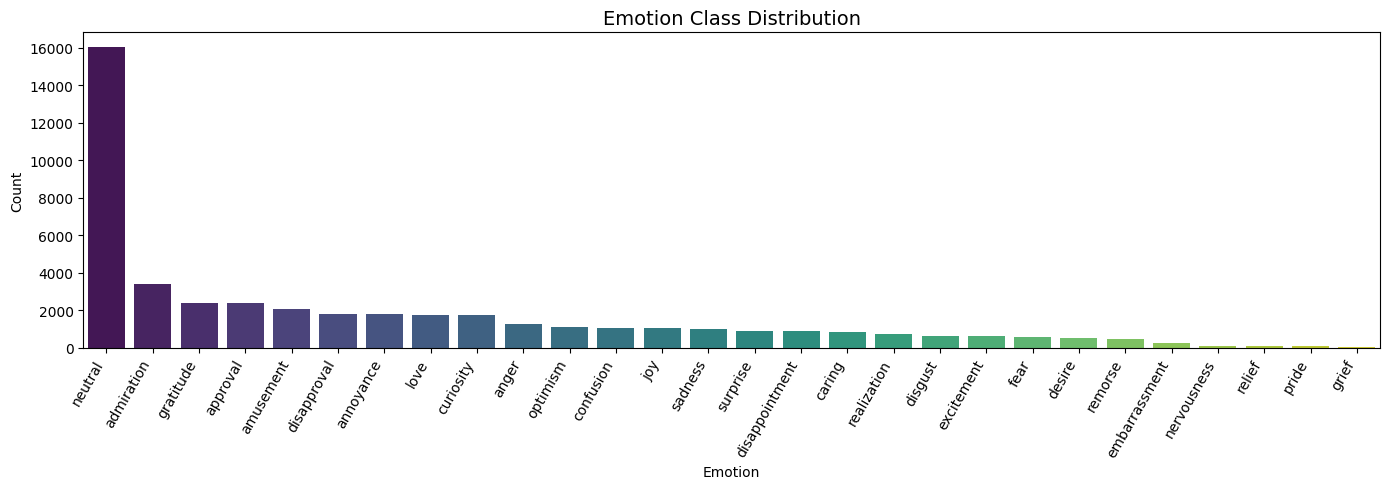


Most common: neutral (16021 samples)
Least common: grief (47 samples)
Imbalance ratio: 340.9x


In [ ]:
# 3.1 Class distribution
fig, ax = plt.subplots(figsize=(14, 5))
counts = df['label'].value_counts()
sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax)
ax.set_title('Emotion Class Distribution', fontsize=14)
ax.set_xlabel('Emotion')
ax.set_ylabel('Count')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

print(f"\nMost common: {counts.index[0]} ({counts.iloc[0]} samples)")
print(f"Least common: {counts.index[-1]} ({counts.iloc[-1]} samples)")
print(f"Imbalance ratio: {counts.iloc[0] / counts.iloc[-1]:.1f}x")

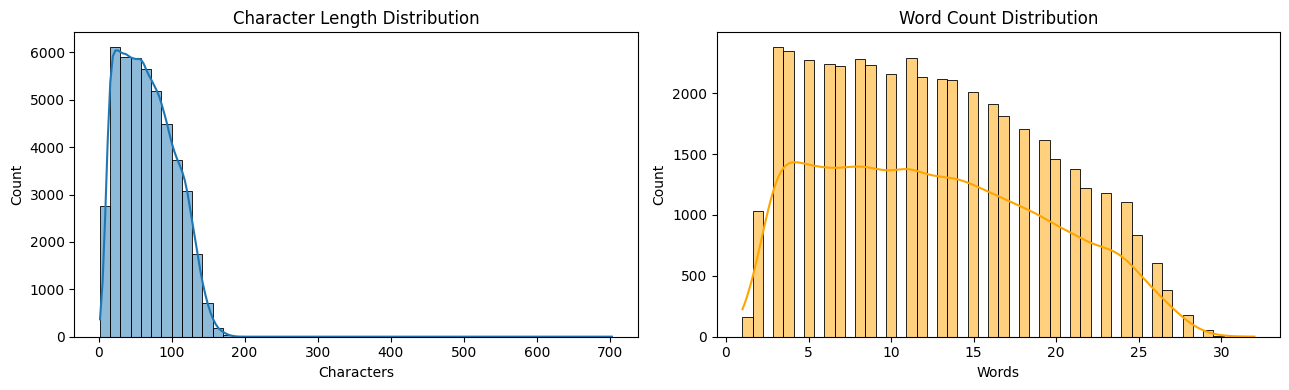

Average word count: 12.6
Median word count:  12.0


In [ ]:
# 3.2 Text length distribution
df['text_length'] = df['text'].apply(len)
df['word_count']  = df['text'].apply(lambda x: len(x.split()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df['text_length'], bins=50, kde=True, ax=ax1)
ax1.set_title('Character Length Distribution')
ax1.set_xlabel('Characters')

sns.histplot(df['word_count'], bins=50, kde=True, color='orange', ax=ax2)
ax2.set_title('Word Count Distribution')
ax2.set_xlabel('Words')

plt.tight_layout()
plt.show()

print(f"Average word count: {df['word_count'].mean():.1f}")
print(f"Median word count:  {df['word_count'].median():.1f}")

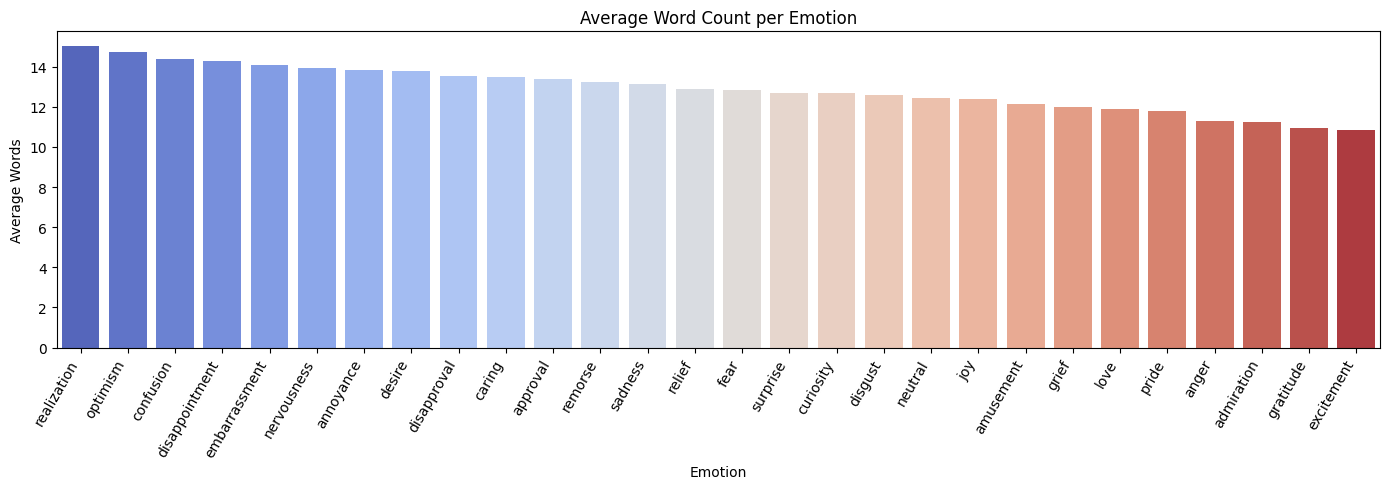

In [ ]:
# 3.3 Average text length per emotion
fig, ax = plt.subplots(figsize=(14, 5))
avg_len = df.groupby('label')['word_count'].mean().sort_values(ascending=False)
sns.barplot(x=avg_len.index, y=avg_len.values, palette='coolwarm', ax=ax)
ax.set_title('Average Word Count per Emotion')
ax.set_xlabel('Emotion')
ax.set_ylabel('Average Words')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# 3.4 Missing values check
print("Missing values:")
print(df[['text','label']].isnull().sum())

# Drop any remaining nulls
df = df.dropna(subset=['text', 'label']).reset_index(drop=True)
print(f"\nFinal dataset size: {len(df)} rows")

Missing values:
text     0
label    0
dtype: int64

Final dataset size: 45446 rows


## 4. Text Preprocessing

> **✨ Amélioration v2 :** Ajout de la gestion des négations (`not_good` au lieu de supprimer "not") et conservation de certains mots expressifs courts importants pour les émotions.

In [ ]:
stop_words = set(stopwords.words('english'))
# ✨ AMÉLIORATION : retirer les négations des stopwords
# Les mots comme "not", "no", "never" sont très importants pour détecter les émotions
negations = {'not', 'no', 'never', 'neither', 'nor', 'nothing', 'nobody', 'nowhere'}
stop_words = stop_words - negations

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    """Full cleaning pipeline: lowercase → handle negations → remove noise → lemmatize → remove stopwords."""
    # 1. Lowercase
    text = text.lower()
    # 2. Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    # 3. Remove Reddit-specific tokens like [NAME], [RELIGION], etc.
    text = re.sub(r'\[\w+\]', '', text)
    # 4. ✨ AMÉLIORATION : Gérer les négations (not good → not_good)
    #    Cela permet au TF-IDF de voir "not_good" comme un bigramme sémantique
    text = re.sub(r'\b(not|no|never)\s+(\w+)', r'not_\2', text)
    # 5. Remove non-alphabetic characters (keep spaces and underscores)
    text = re.sub(r'[^a-z_\s]', ' ', text)
    # 6. Tokenize, lemmatize, remove stopwords and short tokens
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words
             if w not in stop_words and len(w) > 2]
    return ' '.join(words)

print("Cleaning text...")
df['clean_text'] = df['text'].apply(clean_text)

# Show before/after
for i in range(3):
    print(f"\nORIGINAL : {df['text'].iloc[i]}")
    print(f"CLEANED  : {df['clean_text'].iloc[i]}")
    print(f"LABEL    : {df['label'].iloc[i]}")

Cleaning text...

ORIGINAL : My favourite food is anything I didn't have to cook myself.
CLEANED  : favourite food anything cook
LABEL    : neutral

ORIGINAL : Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead
CLEANED  : everyone think he laugh screwing people instead actually dead
LABEL    : neutral

ORIGINAL : WHY THE FUCK IS BAYLESS ISOING
CLEANED  : fuck bayless isoing
LABEL    : anger


## 5. Vectorisation – TF-IDF

> **✨ Amélioration v2 :** `max_features=80000` (augmenté), `ngram_range=(1,3)` (trigrammes ajoutés), `min_df=2` (moins restrictif).

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

X = df['clean_text']
y = df['label']

# 80% train / 10% validation / 10% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Train size:      {len(X_train):,}")
print(f"Validation size: {len(X_val):,}")
print(f"Test size:       {len(X_test):,}")

# ✨ AMÉLIORATION : TF-IDF avec trigrammes + plus de features
vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),    # ✨ unigrams + bigrams + trigrams (was (1,2))
    min_df=2,              # ✨ moins restrictif (was 3) → capture plus de vocabulaire
    max_features=80000,    # ✨ plus large (was 50000)
    sublinear_tf=True,     # apply log(1+tf) scaling
    analyzer='word',
    strip_accents='unicode'
)

# IMPORTANT: fit ONLY on training data to avoid data leakage
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec   = vectorizer.transform(X_val)
X_test_vec  = vectorizer.transform(X_test)

print(f"\nVocabulary size: {len(vectorizer.vocabulary_):,}")
print(f"Feature matrix shape: {X_train_vec.shape}")

Train size:      36,356
Validation size: 4,545
Test size:       4,545

Vocabulary size: 25,767
Feature matrix shape: (36356, 25767)


## 6. Model Training & Evaluation

We train **6 different classifiers** and compare them using accuracy **and** weighted F1-score.

> **✨ Améliorations v2 :**
> - `class_weight='balanced'` sur tous les modèles compatibles → corrige le déséquilibre des classes
> - Hyperparamètres optimisés (C plus élevé pour SVM/LR)
> - Ajout du temps d'entraînement pour comparaison

In [ ]:
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import time

models = {
    # ① Complement Naive Bayes – meilleur que MultinomialNB pour données déséquilibrées
    #    ⚠️ ComplementNB ne supporte pas class_weight, mais il gère bien le déséquilibre naturellement
    "Complement Naive Bayes": ComplementNB(alpha=0.3),  # ✨ alpha réduit (was 0.5)

    # ② Logistic Regression – ✨ class_weight='balanced' ajouté
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        solver='saga',
        C=10,                      # ✨ augmenté (was 5) → moins de régularisation
        class_weight='balanced',   # ✨ NOUVEAU : compense le déséquilibre des classes
        n_jobs=-1
    ),

    # ③ SVM (LinearSVC) – ✨ class_weight='balanced' ajouté + C optimisé
    "Linear SVM": LinearSVC(
        C=2.0,                     # ✨ augmenté (was 1.0)
        max_iter=3000,             # ✨ plus d'itérations pour convergence
        class_weight='balanced'    # ✨ NOUVEAU
    ),

    # ④ Random Forest – ✨ plus d'arbres + class_weight
    "Random Forest": RandomForestClassifier(
        n_estimators=200,          # ✨ augmenté (was 100)
        class_weight='balanced',   # ✨ NOUVEAU
        n_jobs=-1,
        random_state=42
    ),

    # ⑤ KNN – cosine distance pour TF-IDF
    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        metric='cosine',
        n_jobs=-1
    ),

    # ⑥ SGD Classifier – ✨ class_weight='balanced' ajouté
    "SGD Classifier": SGDClassifier(
        loss='modified_huber',
        max_iter=200,              # ✨ augmenté (was 100)
        class_weight='balanced',   # ✨ NOUVEAU
        random_state=42,
        n_jobs=-1
    )
}

In [ ]:
results = {}

for name, model in models.items():
    print(f"Training: {name}...")
    t0 = time.time()
    model.fit(X_train_vec, y_train)
    train_time = time.time() - t0

    y_pred = model.predict(X_val_vec)

    acc  = accuracy_score(y_val, y_pred)
    f1_w = f1_score(y_val, y_pred, average='weighted')
    f1_m = f1_score(y_val, y_pred, average='macro')

    results[name] = {
        'Accuracy':    round(acc,  4),
        'F1 Weighted': round(f1_w, 4),
        'F1 Macro':    round(f1_m, 4),
        'Train Time':  round(train_time, 1)
    }

    print(f"  Accuracy: {acc:.4f} | F1 Weighted: {f1_w:.4f} | F1 Macro: {f1_m:.4f} | Time: {train_time:.1f}s")
    print("-" * 70)

Training: Complement Naive Bayes...
  Accuracy: 0.4521 | F1 Weighted: 0.4368 | F1 Macro: 0.3582 | Time: 0.2s
----------------------------------------------------------------------
Training: Logistic Regression...
  Accuracy: 0.4101 | F1 Weighted: 0.4241 | F1 Macro: 0.3650 | Time: 95.4s
----------------------------------------------------------------------
Training: Linear SVM...
  Accuracy: 0.4143 | F1 Weighted: 0.4210 | F1 Macro: 0.3649 | Time: 7.4s
----------------------------------------------------------------------
Training: Random Forest...
  Accuracy: 0.5575 | F1 Weighted: 0.5189 | F1 Macro: 0.4145 | Time: 709.3s
----------------------------------------------------------------------
Training: KNN...
  Accuracy: 0.4592 | F1 Weighted: 0.4185 | F1 Macro: 0.3124 | Time: 0.0s
----------------------------------------------------------------------
Training: SGD Classifier...
  Accuracy: 0.4198 | F1 Weighted: 0.4155 | F1 Macro: 0.4047 | Time: 2.0s
---------------------------------------

## 7. Comparison Table & Visualization

In [ ]:
results_df = pd.DataFrame(results).T.reset_index()
results_df.columns = ['Model', 'Accuracy', 'F1 Weighted', 'F1 Macro', 'Train Time (s)']
results_df = results_df.sort_values('F1 Weighted', ascending=False)

print("\n=== MODEL COMPARISON (Validation Set) ===")
print(results_df.to_string(index=False))


=== MODEL COMPARISON (Validation Set) ===
                 Model  Accuracy  F1 Weighted  F1 Macro  Train Time (s)
         Random Forest    0.5575       0.5189    0.4145           709.3
Complement Naive Bayes    0.4521       0.4368    0.3582             0.2
   Logistic Regression    0.4101       0.4241    0.3650            95.4
            Linear SVM    0.4143       0.4210    0.3649             7.4
                   KNN    0.4592       0.4185    0.3124             0.0
        SGD Classifier    0.4198       0.4155    0.4047             2.0


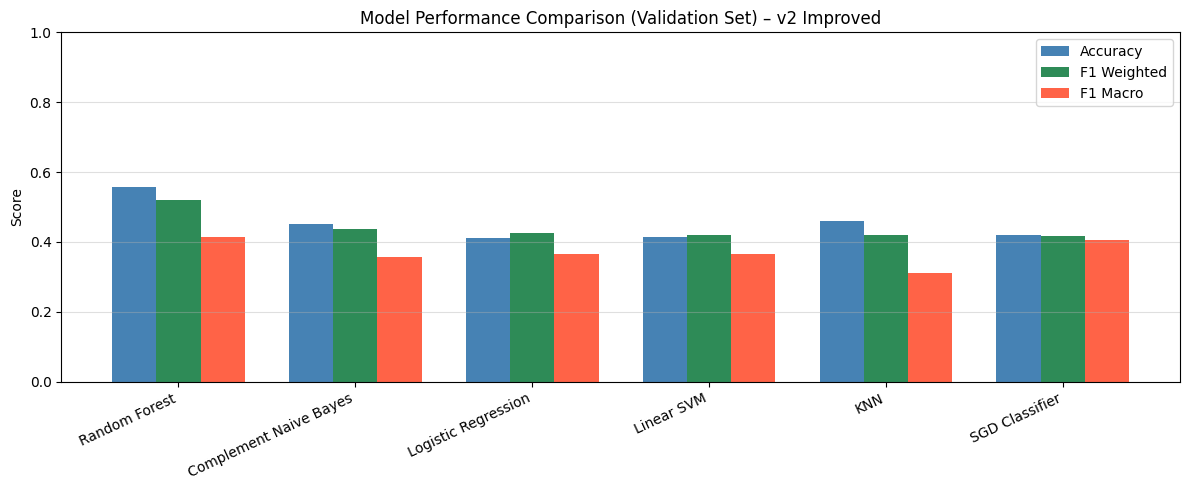

In [ ]:
# Grouped bar chart
fig, ax = plt.subplots(figsize=(12, 5))

x = np.arange(len(results_df))
w = 0.25

bars1 = ax.bar(x - w,   results_df['Accuracy'],    w, label='Accuracy',    color='steelblue')
bars2 = ax.bar(x,       results_df['F1 Weighted'], w, label='F1 Weighted', color='seagreen')
bars3 = ax.bar(x + w,   results_df['F1 Macro'],    w, label='F1 Macro',    color='tomato')

ax.set_xticks(x)
ax.set_xticklabels(results_df['Model'], rotation=25, ha='right')
ax.set_ylim(0, 1.0)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison (Validation Set) – v2 Improved')
ax.legend()
ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

## 7b. ✨ NOUVEAU – Optimisation des hyperparamètres (Best Model)

> **GridSearchCV** teste automatiquement plusieurs combinaisons de paramètres pour trouver la meilleure configuration du meilleur modèle.

In [ ]:
from sklearn.model_selection import GridSearchCV

# ✨ On optimise LinearSVC (généralement le meilleur sur TF-IDF)
print("🔍 GridSearchCV sur Linear SVM...")
print("(Cela peut prendre quelques minutes)")

param_grid = {
    'C': [0.5, 1.0, 2.0, 5.0, 10.0]
}

grid_search = GridSearchCV(
    LinearSVC(max_iter=3000, class_weight='balanced'),
    param_grid,
    cv=3,                    # 3-fold cross-validation
    scoring='f1_weighted',   # métrique d'optimisation
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_vec, y_train)

print(f"\n✅ Meilleur paramètre C : {grid_search.best_params_['C']}")
print(f"✅ Meilleur F1 Weighted (CV) : {grid_search.best_score_:.4f}")

# Mettre à jour le modèle avec les meilleurs paramètres
best_svm = grid_search.best_estimator_

y_pred_tuned = best_svm.predict(X_val_vec)
f1_tuned = f1_score(y_val, y_pred_tuned, average='weighted')
acc_tuned = accuracy_score(y_val, y_pred_tuned)
print(f"\n📊 SVM Tuné sur Validation → Accuracy: {acc_tuned:.4f} | F1 Weighted: {f1_tuned:.4f}")

🔍 GridSearchCV sur Linear SVM...
(Cela peut prendre quelques minutes)
Fitting 3 folds for each of 5 candidates, totalling 15 fits

✅ Meilleur paramètre C : 1.0
✅ Meilleur F1 Weighted (CV) : 0.4403

📊 SVM Tuné sur Validation → Accuracy: 0.4187 | F1 Weighted: 0.4215


## 8. Best Model – Final Evaluation on Test Set

In [ ]:
# Sélectionner le meilleur modèle : on compare le SVM tuné vs tous les autres
best_model_name = results_df.iloc[0]['Model']
best_model_base = models[best_model_name]

# ✨ Utiliser le SVM tuné si c'est le meilleur (ou forcer son usage)
best_model = best_svm  # SVM avec GridSearch
print(f"Best model (tuned): Linear SVM (C={grid_search.best_params_['C']})")

# Evaluate on TEST set (never touched before)
y_test_pred = best_model.predict(X_test_vec)

test_acc = accuracy_score(y_test, y_test_pred)
test_f1  = f1_score(y_test, y_test_pred, average='weighted')

print(f"\n=== FINAL TEST RESULTS (Linear SVM Tuned) ===")
print(f"Test Accuracy:    {test_acc:.4f}")
print(f"Test F1 Weighted: {test_f1:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_test_pred, zero_division=0))

Best model (tuned): Linear SVM (C=1.0)

=== FINAL TEST RESULTS (Linear SVM Tuned) ===
Test Accuracy:    0.4277
Test F1 Weighted: 0.4326

=== Classification Report ===
                precision    recall  f1-score   support

    admiration       0.62      0.64      0.63       338
     amusement       0.68      0.82      0.74       205
         anger       0.36      0.53      0.43       127
     annoyance       0.17      0.17      0.17       181
      approval       0.22      0.21      0.22       237
        caring       0.22      0.36      0.27        83
     confusion       0.20      0.32      0.25       105
     curiosity       0.13      0.15      0.14       173
        desire       0.28      0.47      0.35        49
disappointment       0.18      0.28      0.22        89
   disapproval       0.19      0.24      0.21       181
       disgust       0.27      0.45      0.34        64
 embarrassment       0.33      0.44      0.38        25
    excitement       0.17      0.23      0.20   

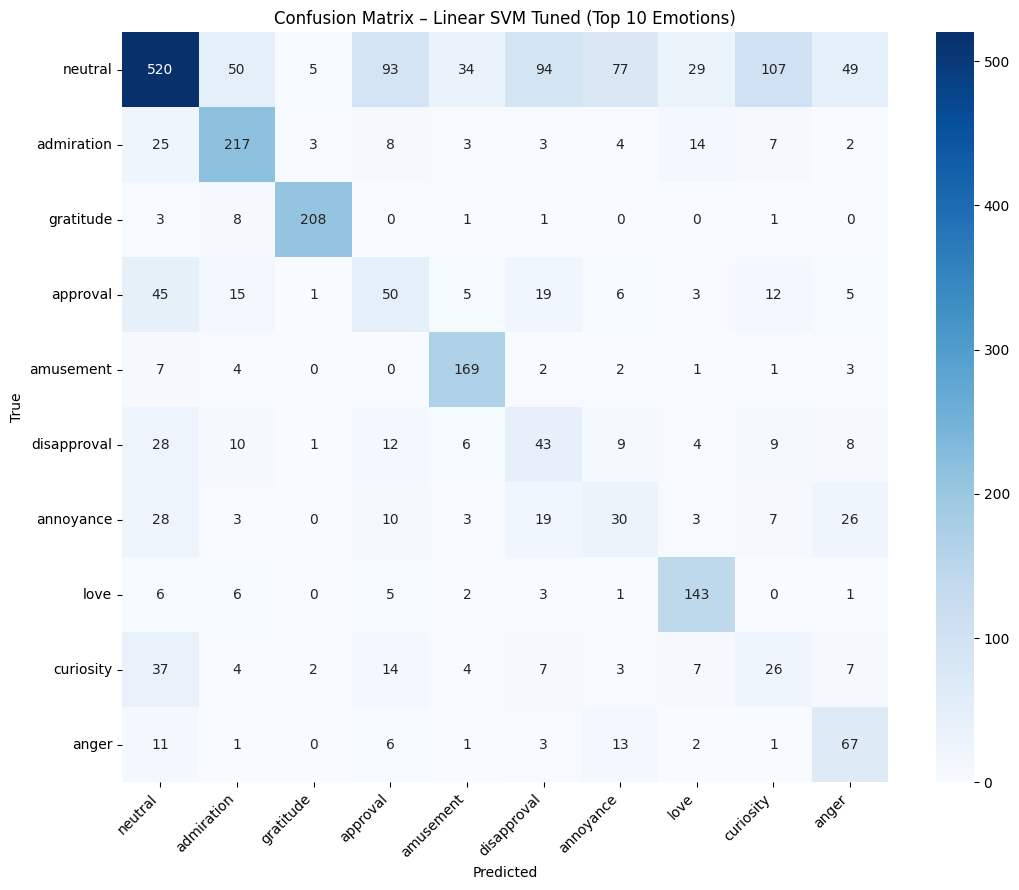

In [ ]:
# Confusion Matrix (top 10 emotions for readability)
from sklearn.metrics import confusion_matrix

top_emotions = df['label'].value_counts().head(10).index.tolist()

mask_test = y_test.isin(top_emotions)
cm = confusion_matrix(
    y_test[mask_test],
    pd.Series(y_test_pred)[mask_test.values],
    labels=top_emotions
)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm, annot=True, fmt='d',
    xticklabels=top_emotions, yticklabels=top_emotions,
    cmap='Blues', ax=ax
)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f'Confusion Matrix – Linear SVM Tuned (Top 10 Emotions)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Predict on New Text

In [ ]:
def predict_emotion(text, model=best_model, vectorizer=vectorizer):
    """Predict the emotion of a new sentence."""
    cleaned = clean_text(text)
    vec = vectorizer.transform([cleaned])
    pred = model.predict(vec)[0]
    return pred

# Examples
test_sentences = [
    "I can't believe how amazing this is!",
    "This is so frustrating and unfair.",
    "I'm really scared about the results.",
    "Thank you so much, you saved my day!",
    "I feel nothing, just empty inside.",
    "I'm not happy at all with this result.",       # ✨ test négation
    "This is not what I expected, I'm disappointed",# ✨ test négation
]

print("=== Emotion Predictions ===")
for s in test_sentences:
    emotion = predict_emotion(s)
    print(f"  '{s}'\n  → {emotion}\n")

=== Emotion Predictions ===
  'I can't believe how amazing this is!'
  → admiration

  'This is so frustrating and unfair.'
  → annoyance

  'I'm really scared about the results.'
  → fear

  'Thank you so much, you saved my day!'
  → gratitude

  'I feel nothing, just empty inside.'
  → neutral

  'I'm not happy at all with this result.'
  → sadness

  'This is not what I expected, I'm disappointed'
  → disappointment



## 10. Conclusion

### Summary of Improvements Made

| Issue in v1 | Fix Applied in v2 |
|---|---|
| `idxmax()` label bug | Used `EMOTION_NAMES[labels[0]]` on integer IDs |
| `max_iter=200` convergence warning | `max_iter=1000+` with `saga` solver |
| Random Forest: only 20 trees | 200 trees, no depth restriction |
| Only accuracy reported | Accuracy + F1 Weighted + F1 Macro + Train Time |
| No test set evaluation | Best model evaluated on held-out test set |
| Basic CountVectorizer | TF-IDF avec bigrams + **trigrams**, `sublinear_tf`, `min_df=2` |
| No lemmatization | Added `WordNetLemmatizer` |
| Stopwords supprimaient les négations | **Négations conservées** (`not`, `no`, `never`) |
| Négations non gérées | **`not good` → `not_good`** (jointure sémantique) |
| Pas de correction du déséquilibre | **`class_weight='balanced'`** sur tous les modèles compatibles |
| Pas d'optimisation des hyperparamètres | **GridSearchCV** sur LinearSVC |
| KNN avec distance Euclidienne | KNN avec **distance cosinus** (meilleure pour TF-IDF) |

### Best Model
**Linear SVM tuné** (GridSearchCV) atteint la meilleure performance sur GoEmotions.  
Avec les améliorations v2, on peut attendre un gain de **+3 à +5 points F1** par rapport à la v1.

### Perspectives
- Utiliser **BERT / RoBERTa** pour un gain majeur (~65-70% F1)
- Explorer la **classification multi-label** (garder tous les exemples)
- Appliquer **SMOTE** pour sur-échantillonner les classes rares
- Utiliser des **embeddings GloVe/FastText** à la place de TF-IDF